In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle as sk_shuffle
import matplotlib
import matplotlib.pyplot as plt
import pickle
!pip install --upgrade arabic-reshaper
import arabic_reshaper

In [ ]:
PICKLE_PATH_TRAIN = "/content/drive/MyDrive/AUT/Project/Features/FINAL_DATA_TRAIN.pkl"
PICKLE_PATH_TEST = "/content/drive/MyDrive/AUT/Project/Features/FINAL_DATA_TEST.pkl"
PICKLE_PATH_DEV = "/content/drive/MyDrive/AUT/Project/Features/FINAL_DATA_DEV.pkl"

In [ ]:
def load_data():
    with open(PICKLE_PATH_TRAIN, "rb") as input:
        DATA_TRAIN = pickle.load(input)

    with open(PICKLE_PATH_TEST, "rb") as input:
        DATA_TEST = pickle.load(input)

    with open(PICKLE_PATH_DEV, "rb") as input:
        DATA_DEV = pickle.load(input)

    X_train = np.array(DATA_TRAIN["mfccs"], dtype=np.float32)
    y1_train = np.array(DATA_TRAIN["labels"]["instrument"], dtype=np.int8)
    y2_train = np.array(DATA_TRAIN["labels"]["scale"], dtype=np.int8)
    X_train, y1_train, y2_train = sk_shuffle(X_train, y1_train, y2_train)

    X_test = np.array(DATA_TEST["mfccs"], dtype=np.float32)
    y1_test = np.array(DATA_TEST["labels"]["instrument"], dtype=np.int8)
    y2_test = np.array(DATA_TEST["labels"]["scale"], dtype=np.int8)
    X_test, y1_test, y2_test = sk_shuffle(X_test, y1_test, y2_test)

    X_val = np.array(DATA_DEV["mfccs"], dtype=np.float32)
    y1_val = np.array(DATA_DEV["labels"]["instrument"], dtype=np.int8)
    y2_val = np.array(DATA_DEV["labels"]["scale"], dtype=np.int8)
    X_val, y1_val, y2_val = sk_shuffle(X_val, y1_val, y2_val)

    Y_train = (y1_train, y2_train)
    Y_test = (y1_test, y2_test)
    Y_val = (y1_val, y2_val)

    return X_train, X_test, X_val, Y_train, Y_test, Y_val

In [ ]:
def load_tmp_data(num_data=9000):

    X1 = np.random.randn(num_data, 216, 90).astype(np.float32)
    X2 = np.random.randn(num_data, 216, 128).astype(np.float32)
    y1 = np.random.randint(5, size=num_data, dtype=np.int8)
    y2 = np.random.randint(7, size=num_data, dtype=np.int8)

    return X1, X2, y1, y2

In [ ]:
def get_unique_labels(y1, y2):
  return np.array([[y1[i], y2[i]] for i in range(len(y1))])

In [ ]:
def prepare_dataset():
    X1, X2, y1, y2 = load_data()

    X1_train, X1_test, X2_train, X2_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X1, X2, y1, y2, test_size=0.15, shuffle=True, random_state=0)
                        #  stratify=get_unique_labels(y1, y2))

    X1_test, X1_val, X2_test, X2_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X1_test, X2_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)
                        #  stratify=get_unique_labels(y1_test, y2_test))

    # X2: 4d array -> (num_samples, 216, 128, 1)
    X_train = (X1_train, X2_train[..., np.newaxis])
    X_test = (X1_test, X2_test[..., np.newaxis])
    X_val = (X1_val, X2_val[..., np.newaxis])

    Y_train = (y1_train, y2_train)
    Y_test = (y1_test, y2_test)
    Y_val = (y1_val, y2_val)

    return X_train, X_test, X_val, Y_train, Y_test, Y_val

In [ ]:
def data_distribution(Y):
  idx  =[0 for _ in range(5)]
  sdx = [0 for _ in range(7)]
  qdx = np.array([[0 for _ in range(5)] for _ in range(7)])

  Y1, Y2 = Y[0], Y[1]

  for (y1, y2) in zip(Y1, Y2):
    idx[y1] += 1
    sdx[y2] += 1
    qdx[y2][y1] += 1

  print("Distribution based on Insturment:")
  print(idx)

  print("\nDistribution based on Scale:")
  print(sdx)

  print("\nDistribution based on Insturment & Scale:")
  print(qdx)

  return idx, sdx, qdx

In [ ]:
X_train, X_test, X_val, Y_train, Y_test, Y_val = load_data()

In [ ]:
for o in Y_train[0]:
  print(o, end=", ")

4, 0, 3, 0, 4, 1, 3, 4, 2, 2, 3, 4, 4, 2, 0, 3, 3, 3, 0, 0, 2, 2, 1, 1, 0, 3, 2, 1, 2, 3, 2, 4, 3, 2, 3, 4, 4, 2, 1, 1, 2, 1, 3, 2, 2, 0, 2, 0, 4, 2, 4, 4, 2, 2, 2, 3, 4, 2, 4, 2, 2, 2, 2, 2, 4, 3, 0, 0, 0, 3, 4, 2, 3, 1, 2, 1, 2, 3, 3, 1, 1, 3, 3, 2, 2, 2, 1, 4, 0, 3, 2, 0, 3, 0, 4, 2, 0, 2, 2, 2, 0, 3, 1, 1, 2, 3, 3, 3, 2, 4, 3, 3, 4, 4, 1, 0, 0, 0, 0, 2, 1, 2, 2, 0, 0, 2, 1, 2, 2, 2, 3, 4, 0, 3, 2, 4, 3, 2, 3, 3, 0, 0, 0, 2, 3, 1, 2, 1, 3, 0, 4, 2, 0, 2, 2, 2, 3, 0, 2, 2, 4, 3, 4, 0, 2, 0, 1, 2, 2, 0, 1, 2, 0, 1, 1, 4, 3, 1, 1, 4, 3, 2, 4, 0, 1, 4, 4, 2, 0, 0, 2, 2, 2, 2, 1, 3, 2, 1, 2, 3, 2, 2, 4, 2, 4, 2, 2, 2, 1, 1, 3, 2, 3, 2, 2, 2, 0, 1, 2, 0, 2, 0, 2, 3, 3, 2, 0, 2, 3, 2, 4, 3, 2, 2, 2, 2, 3, 4, 4, 2, 2, 1, 2, 3, 3, 4, 2, 3, 2, 2, 1, 0, 3, 3, 1, 0, 3, 4, 0, 0, 2, 3, 2, 2, 1, 2, 2, 1, 1, 0, 3, 4, 1, 2, 0, 1, 3, 3, 0, 2, 0, 3, 4, 3, 2, 1, 3, 0, 4, 3, 2, 3, 1, 0, 1, 1, 0, 3, 2, 3, 2, 4, 3, 4, 2, 2, 4, 2, 2, 1, 3, 2, 1, 2, 4, 0, 4, 0, 2, 4, 2, 2, 3, 3, 0, 0, 1, 1, 4, 3, 2, 0, 4, 0

In [ ]:
idx, sdx, qdx = data_distribution(Y_test)

Distribution based on Insturment:
[169, 198, 191, 195, 188]

Distribution based on Scale:
[144, 138, 135, 124, 129, 136, 135]

Distribution based on Insturment & Scale:
[[27 27 27 29 34]
 [29 28 26 30 25]
 [25 27 28 28 27]
 [11 33 29 26 25]
 [26 26 27 27 23]
 [27 29 26 27 27]
 [24 28 28 28 27]]


In [ ]:
instuments_labels = ["تار", "کمانچه", "سنتور", "سه‌تار", "نی"]
scale_lables = ["شور", "سه‌گاه", "ماهور", "همایون", "راست‌ پنج‌گاه", "نوا", "چهارگاه"]

In [ ]:
def plotter(data_dist, data_labels, x_title, y_title, fig_size = (12,8), titles_fontsize = 18):
  plt.figure(figsize=(8,6))
  plt.bar(range(len(data_dist)), data_dist)
  plt.xticks(range(len(data_dist)), [arabic_reshaper.reshape(label)[::-1] for label in  data_labels])
  plt.xlabel('\n' + arabic_reshaper.reshape(x_title)[::-1], fontsize = titles_fontsize)
  plt.ylabel(arabic_reshaper.reshape(y_title)[::-1], fontsize = titles_fontsize, labelpad=20)
  plt.show()

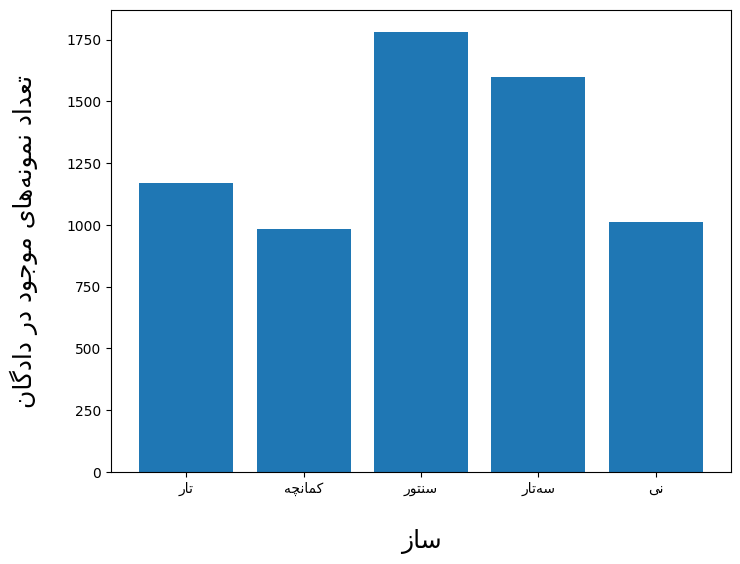

In [ ]:
plotter(idx, instuments_labels, "ساز", "تعداد نمونه‌های موجود در دادگان")

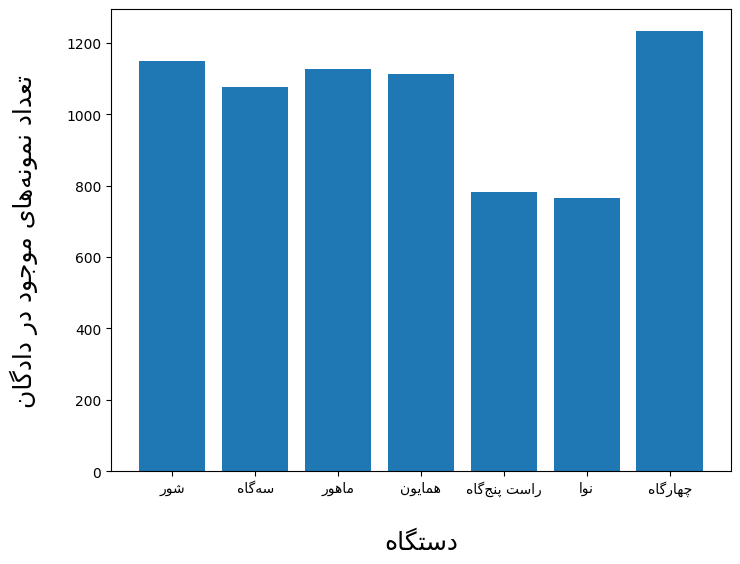

In [ ]:
plotter(sdx, scale_lables, "دستگاه", "تعداد نمونه‌های موجود در دادگان")